In [1]:
from config import Config
from lib import sweep
from plot import plot_grid_search


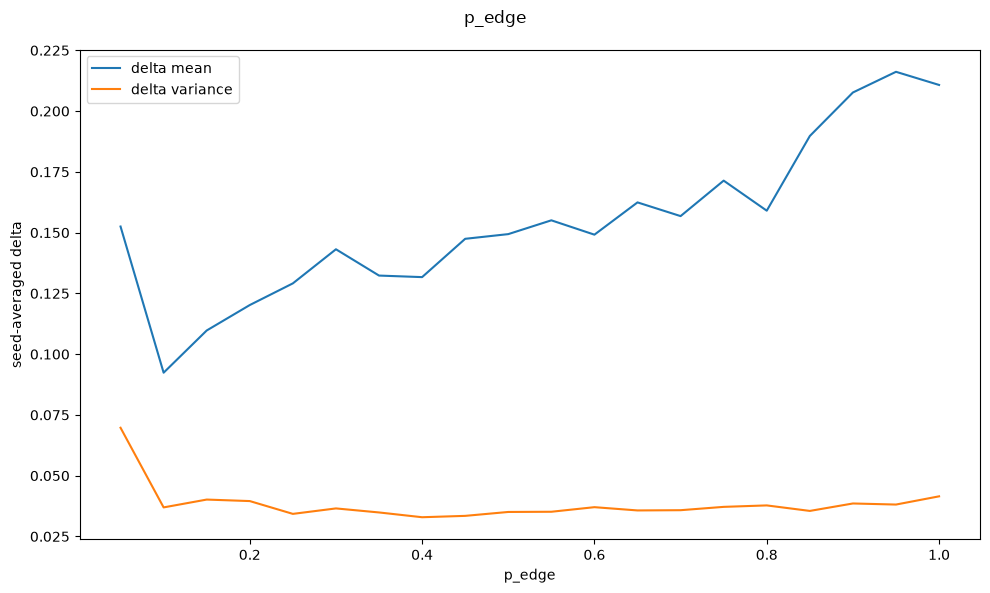

In [ ]:
STEP_SIZE = 4
n_agents = Config().n_agents

results = sweep("random", {"p_edge": [step / 20 for step in range(1, 21)]})
plot_grid_search(results, "p_edge")


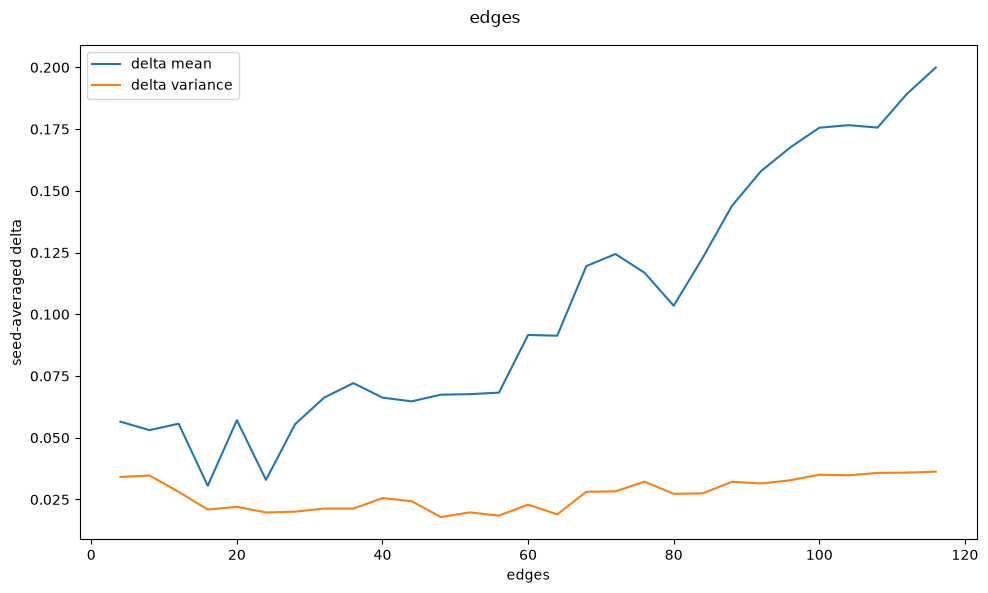

In [ ]:
results = sweep(
    "barbasi", {"edges": [edges for edges in range(STEP_SIZE, n_agents, STEP_SIZE)]}
)
plot_grid_search(results, "edges")


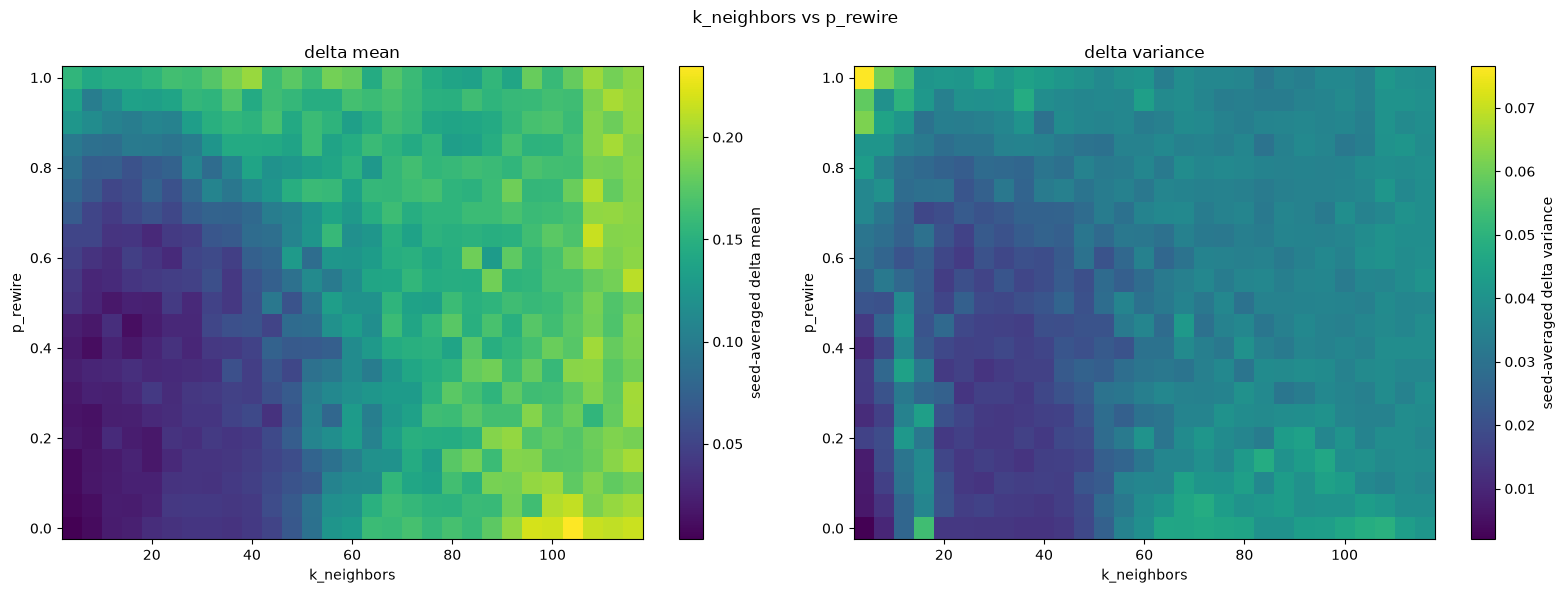

In [6]:
results = sweep(
    "watts",
    {
        "k_neighbors": [step for step in range(STEP_SIZE, n_agents, STEP_SIZE)],
        "p_rewire": [
            step / 20 for step in range(21)
        ],  # conenct from outside of k-neighbours to outsider
    },
)
plot_grid_search(results, "k_neighbors", "p_rewire")


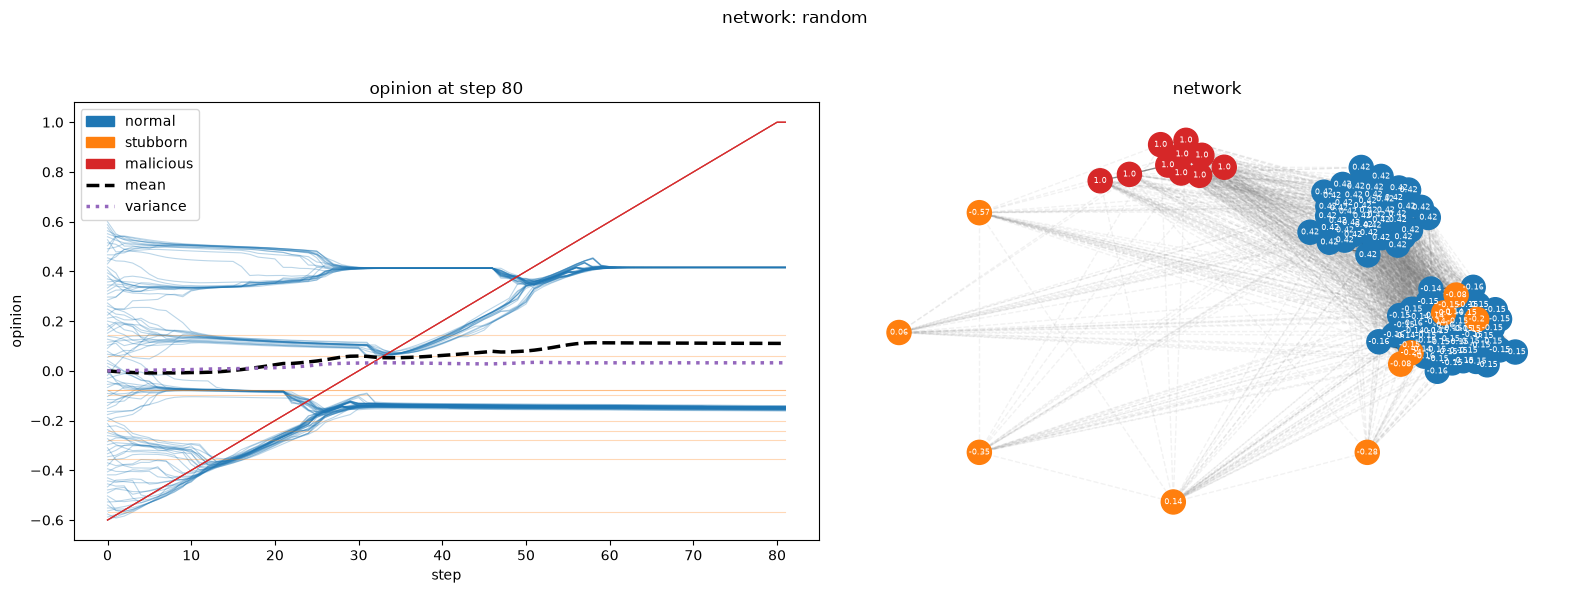

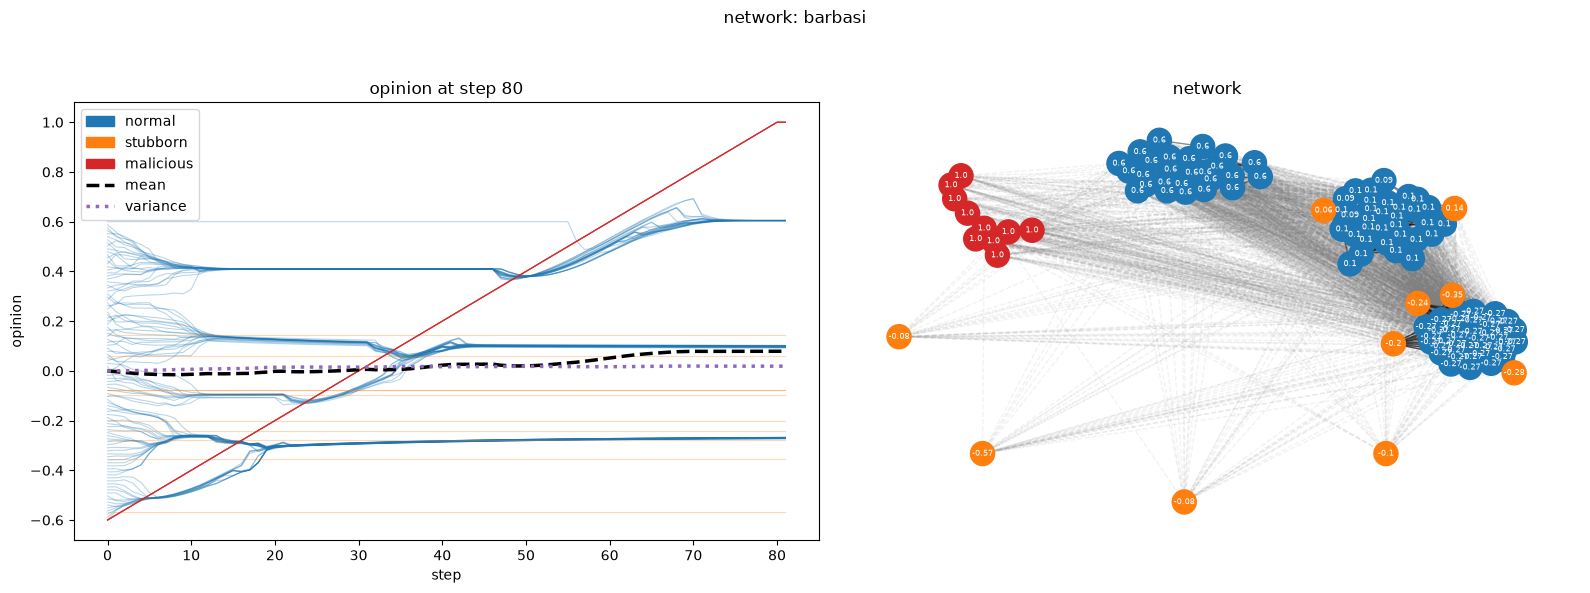

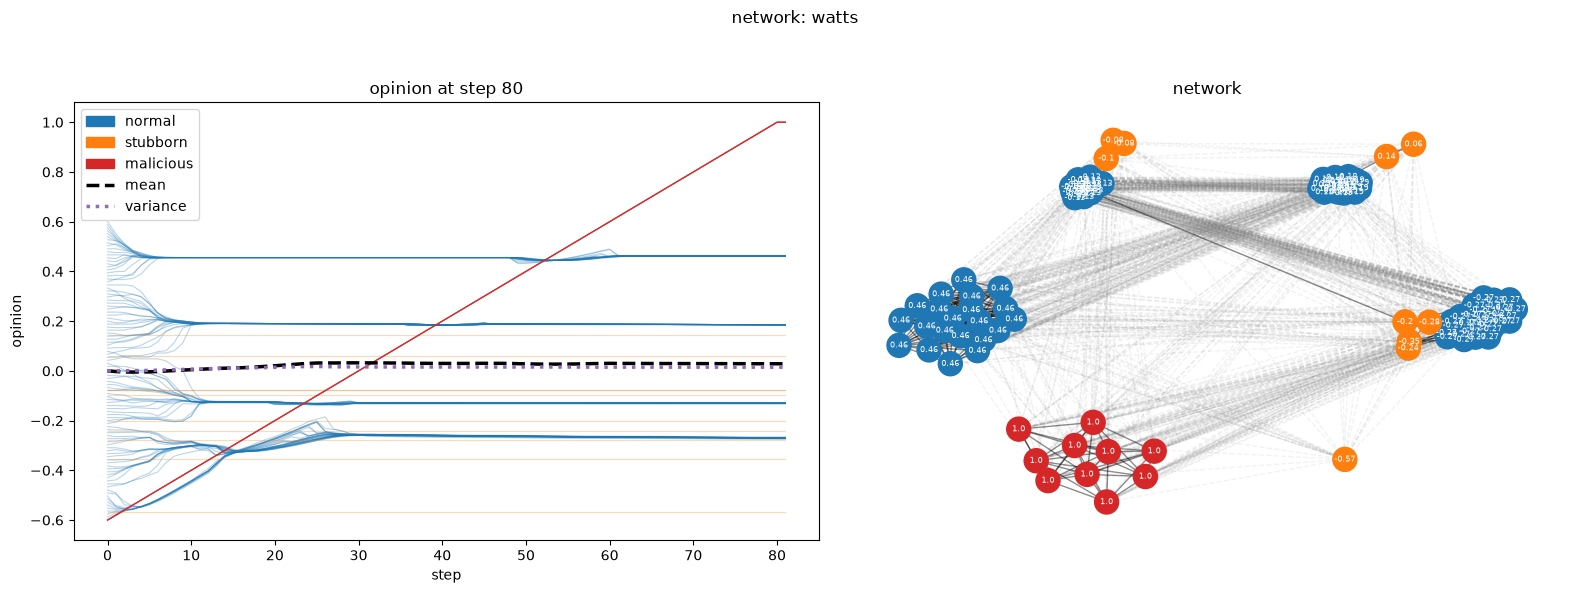

In [ ]:
from config import Config
from lib import init_sim, run_one

STEP_SIZE = 4
cfg = Config()
for kind in cfg.networks:
    sim = init_sim(cfg, kind)
    run_one(cfg, sim, True)


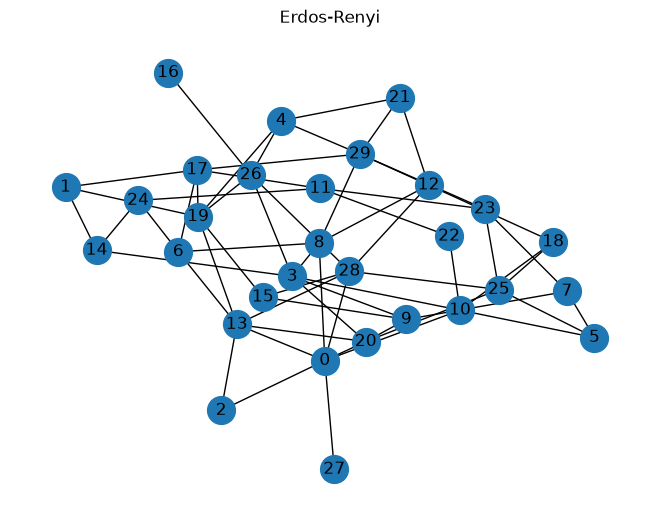

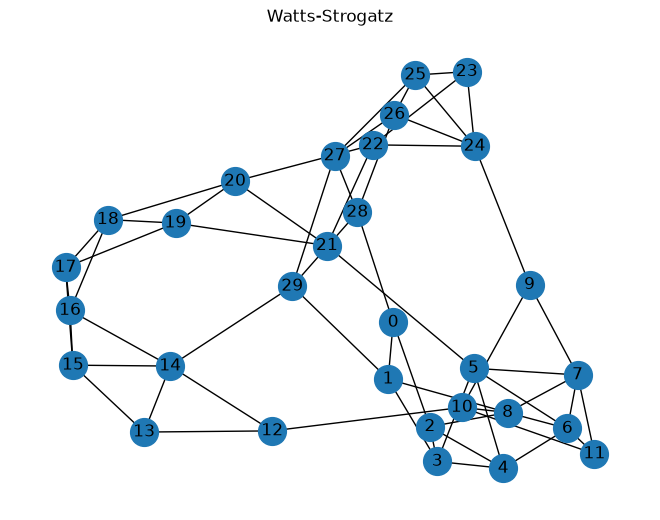

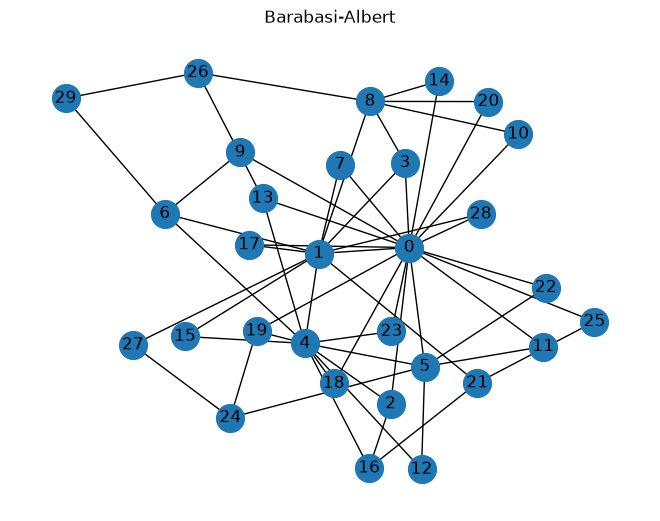

In [2]:
import matplotlib.pyplot as plt
import networkx as nx

n = 30

graphs = {
    "Erdos-Renyi": nx.erdos_renyi_graph(n, p=0.15, seed=42),
    "Watts-Strogatz": nx.watts_strogatz_graph(n, k=4, p=0.1, seed=42),
    "Barabasi-Albert": nx.barabasi_albert_graph(n, m=2, seed=42),
}

for name, G in graphs.items():
    plt.figure()
    nx.draw(
        G,
        with_labels=True,
        node_size=400,
    )
    plt.title(name)
    plt.show()
